<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/03_DDoS_DoS_Detection/QSVM_DDoS_Alonso2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum SVM (PennyLane) for SYN-flood DDoS detection: Alonso et al. (2026) step by step

This notebook rebuilds the experiments of one paper:

Ricardo S. Alonso, Rodrigo Gil-Merino, Guillermo Rivas, Diego Valdeolmillos and Javier Prieto, "Quantum Support Vector Machine for Detecting DDoS Cyber-Attacks", in G. Marreiros et al. (eds.), *Distributed Computing and Artificial Intelligence, Special Sessions II, DCAI 2025*, Lecture Notes in Networks and Systems 1630, Springer, 2026, pp. 255-267. DOI 10.1007/978-3-032-05748-8_21.

**What the notebook does.** It downloads the SYN-flood part of the public CICDDoS2019 dataset (two capture days), cleans it, builds the paper's two data sets (a "full" one for the classical models and a "small" one for the quantum models), and reduces them to 8 PCA components. It then trains a classical RBF-kernel SVM and a small neural network (8x8x16x8x1) on the full set, and three quantum-kernel SVMs on the small set, one for each way of loading data into a circuit that the paper compares: angle embedding, amplitude embedding and the ZZ feature map. The quantum circuits are written with **PennyLane**, as in the paper, and simulated exactly on the CPU. Finally it prints the paper's numbers next to its own, claim by claim.

**How to run it.** Open it in Google Colab, keep the normal CPU runtime and choose Runtime, then Run all. No GPU and no IBM account are needed (the paper used a GPU simulator, which only makes the simulation faster, not different). The first run downloads two large CSV files (0.6 GB and 1.9 GB) from Hugging Face; they are read in pieces, reduced to a small cached sample, and deleted again. `FAST_MODE = True` finishes in about 4 minutes once the data are cached (about 13 minutes including the first download and scan of the two big files); `FAST_MODE = False` (the setting saved in this notebook) repeats the quantum experiments on 20 random draws, uses a finer bandwidth grid and 100 network epochs, and takes about 6 minutes with cached data (the configuration cell lists the budgets).

**What you will get at the end.** Confusion matrices and classification reports in the layout of the paper's Tables 1 to 10, the loss curve and ROC curve of the neural network, the ROC curves of the three quantum SVMs, drawings of the circuits that are really executed, repeated-run averages (the paper's test sets of 100 flows are very noisy), and a verdict for each claim: reproduced, not reached, exceeded, or cannot be checked.

## 1. The paper in one page

**Problem.** Many Internet-of-Things devices are weak and easy to hijack. A botnet made of such devices can flood a server with requests (a DDoS attack) and keep real users out. Classical deep learning can detect these floods but needs a lot of data and computing power, so the authors ask whether a quantum support vector machine (QSVM) can do the job.

**Decision.** For every network flow: is it a TCP **SYN flood** (an attack, called `Syn` in the dataset) or normal traffic (`BENIGN`)? The paper focuses on this single attack type. A SYN flood sends a huge number of connection requests (TCP SYN packets) and never completes the handshake, so the server keeps half-open connections until it runs out of room.

**Method.**
1. Classical models on the **full** data set: an SVM with an RBF kernel and a fully connected neural network with layers 8-8-16-8-1.
2. Quantum models on the **small** data set: a QSVM, i.e. an SVM whose kernel is computed by a quantum circuit, with three ways to encode a flow: **angle embedding** (8 qubits), **amplitude embedding** (3 qubits hold the 2^3 = 8 numbers) and the **ZZ feature map** (8 qubits).
3. Everything is built in Python with scikit-learn and PennyLane.

**Data.** CICDDoS2019 (Hadi et al., 2022 is the paper's reference for the data), CSV version. Identifier-like columns (IP addresses, ports, timestamp, ...) are removed, rows with missing, infinite or duplicate values are dropped, `Syn` and `BENIGN` become two numeric labels, the share of `BENIGN` flows is increased (it is tiny in the original files), and two reduced data sets, **full** and **small**, are drawn. PCA keeps 8 components. The test sets in the paper's tables have 10 000 flows (9 000 Syn, 1 000 BENIGN) for the full set and 100 flows (90 Syn, 10 BENIGN) for the small set.

**Claims to check.**
1. Classical SVM (full set, Tables 1 and 2): accuracy 0.99, BENIGN precision 0.93, recall 1.00, F1 0.96.
2. Neural network (full set, Tables 3 and 4, Figures 2 and 3): accuracy 0.99, BENIGN F1 0.97, a slight overfitting in the loss curves, an excellent ROC curve.
3. QSVM with angle embedding (small set, Tables 5 and 6, Figure 5): accuracy 0.99, BENIGN F1 0.95.
4. QSVM with amplitude embedding (Tables 7 and 8, Figure 6): accuracy 0.97, BENIGN F1 0.84, AUC below 0.9.
5. QSVM with the ZZ feature map (Tables 9 and 10, Figure 7): accuracy 0.97, BENIGN F1 0.82, AUC 0.85.
6. Conclusions: the quantum models do not beat the classical ones in F1; angle embedding comes closest; angle embedding needs more training time than the ZZ map.

A note on the paper's tables. **Table 1** lists 8297 correct Syn flows, but its row must add up to the 9000 Syn flows of the test set (8297 + 73 = 8370). With 8927 the row sums to 9000 and the BENIGN precision becomes 999 / (999 + 73) = 0.93, exactly as Table 2 says, so 8297 is a typing slip for 8927. The notebook uses 8927.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | CICDDoS2019 CSV files, SYN-flood attacks plus benign flows, two capture days | Hugging Face mirror `baalajimaestro/CICDDoS2019`, files `01-12/Syn.csv` (392 BENIGN, 1 582 289 Syn flows) and `03-11/Syn.csv` (35 790 BENIGN, 4 284 751 Syn flows); fallback mirror `RonaldoMPF/CIC-DDoS2019-15C` if the main one is unreachable |
| Features removed | IP addresses, ports, timestamp, "etc." | `# CHOICE:` also flow id, index, `SimillarHTTP` and the capture-direction flag `Inbound` (it is almost a label in this dataset, see Section 5); constant columns dropped |
| Duplicates | removed | removed (exact duplicates; SYN-flood flows are often copies of each other) |
| Label coding | Syn = 0, BENIGN = 1 | `# CHOICE:` Syn = 1 (attack, positive class), BENIGN = 0, as everywhere in this repository; tables are printed in the paper's layout (Syn first) |
| Full set | Size not given; test set 10 000 flows with 9 000 Syn and 1 000 BENIGN | `# CHOICE:` 50 000 flows, 10 % BENIGN, split 80/20, so the test set has exactly the paper's 9 000 + 1 000 flows |
| Small set | Size not given; test set 100 flows with 90 Syn and 10 BENIGN | `# CHOICE:` 500 flows, 10 % BENIGN, split 80/20 (400 training flows, test set exactly 90 + 10) |
| Preprocessing | PCA to 8 components with "sufficient explained variance" | `# CHOICE:` standardise, PCA(8), all fitted on the training split only; for angle and ZZ encoding the components are min-max scaled to [0, pi] (clipping the test values) |
| Classical SVM | RBF kernel, hyper-parameters not given | `SVC(kernel="rbf", C=1.0, gamma="scale")` on the 8 scaled components |
| Neural network | 8x8x16x8x1, fully connected, loss curves; optimiser, epochs, activation not given | `# CHOICE:` scikit-learn `MLPClassifier(hidden_layer_sizes=(8, 16, 8))`, ReLU, Adam, batch 64, one logistic output, trained epoch by epoch with 10 % of the training flows held out for the validation loss (the paper used a deep-learning library; TensorFlow is not needed for this tiny network) |
| Quantum framework | PennyLane, GPU simulator | PennyLane `default.qubit` on the CPU (exact simulation, no shots) |
| Angle embedding | "angle embedding", 8 qubits | `qml.AngleEmbedding` with `RX` rotations, one feature per qubit, no entanglement |
| Amplitude embedding | 3 qubits for the 8 components | `qml.AmplitudeEmbedding(normalize=True)` on the (unscaled) PCA components; the vector is normalised, so only its direction matters |
| ZZ feature map | Figure 4 (not legible in the text), 8 qubits, "deeper circuit" | `# CHOICE:` the standard ZZ feature map of Havlicek et al.: `reps=2`, linear entanglement; per repetition: H, P(2x_i), then for neighbours CNOT, P(2(pi - x_i)(pi - x_j)), CNOT |
| Quantum kernel | overlap of two encoded states (PennyLane kernel) | `K(x, y) = |<phi(x)|phi(y)>|^2`, computed from the exact state vectors and checked against the executed "encode x, undo y" circuit |
| SVM on the kernel | not given | `SVC(kernel="precomputed", C=1.0)` |
| Kernel bandwidth | none mentioned | `# CHOICE:` angles are multiplied by a bandwidth chosen on a validation split of the training flows (angle and ZZ); amplitude embedding is scale-free |
| Repetitions | one run per model | one paper-like draw (draw 0) plus further random draws, because a test set with 10 BENIGN flows is extremely noisy |

## 2. Install the libraries

Colab already has NumPy, pandas, scikit-learn and Matplotlib. We add PennyLane at the version this notebook was tested with, and `huggingface_hub` for the download. If Colab asks you to restart the session after the installation, restart it and run the notebook again from the top. On a machine where PennyLane is already installed, the cell does nothing.

In [1]:
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules

def _missing():
    try:
        import pennylane, huggingface_hub  # noqa: F401
        return False
    except Exception:
        return True

if IN_COLAB or _missing():
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "huggingface_hub"])
    print("Installed. If imports fail below, restart the session (Runtime > Restart session) and Run all again.")
else:
    print("PennyLane already present; nothing to install.")

PennyLane already present; nothing to install.


## 3. Configuration

Every number you may want to change is in the next cell.

* `FAST_MODE = True` is the class demonstration (5 random draws of the quantum experiment, a short bandwidth grid, a shorter neural network training). `FAST_MODE = False` is the full run (the saved setting): 20 random draws, a finer bandwidth grid, 100 training epochs for the network.
* `N_FULL` and `N_SMALL` are the sizes of the paper's two data sets (the paper does not give them; see the table in Section 1). `BENIGN_FRACTION` is the share of normal flows, `TEST_SIZE` the share of flows held out.
* **About the data download.** CICDDoS2019 is public on Hugging Face and needs no token. If you ever point `HF_REPO` at a gated mirror, add your own token in Colab (left side bar, key icon, Secrets, name `HF_TOKEN`); the cell after the configuration looks it up and never prints it.

In [2]:
SEED = 42
FAST_MODE = False                      # True: about 4 min (13 with the first download). False: full run, about 6 min with cached data

# data
HF_REPO = "baalajimaestro/CICDDoS2019"
HF_FILES = ["01-12/Syn.csv", "03-11/Syn.csv"]      # SYN-flood files of the two capture days
HF_REPO_FALLBACK = "RonaldoMPF/CIC-DDoS2019-15C"   # reduced mirror, used only if the main one fails
DATA_SOURCE = "huggingface"            # "huggingface" or "path" (a folder that already holds the two CSV files)
LOCAL_PATH = ""                        # used when DATA_SOURCE == "path"
DATA_DIR = "qc118_data"                # cache directory (created if needed, only small files are kept)
DELETE_RAW = True                      # delete the big downloaded CSV files after they were read
ATTACK_KEEP = 0.12                     # CHOICE: share of de-duplicated Syn flows kept while scanning
DROP_INBOUND = True                    # CHOICE: drop the capture-direction flag 'Inbound' (near-label, Section 5)

# the paper's two data sets (sizes are CHOICEs, the paper does not give them)
N_FULL = 50_000                        # classical models: test set = 10 000 flows (9 000 Syn + 1 000 BENIGN)
N_SMALL = 500                          # quantum models: test set = 100 flows (90 Syn + 10 BENIGN)
BENIGN_FRACTION = 0.10
TEST_SIZE = 0.20
N_COMPONENTS = 8                       # PCA components = qubits (angle, ZZ); 3 qubits hold 8 amplitudes
SVM_C = 1.0
SHOTS = None                           # exact simulation (no sampling noise)
IBM_TOKEN = ""                         # not needed: everything is simulated exactly

if FAST_MODE:
    N_DRAWS = 5                        # random draws of the small data set (draw 0 = paper-like single run)
    BANDWIDTH_GRID = [0.25, 0.5, 1.0]
    ANN_EPOCHS = 30
else:
    N_DRAWS = 20
    BANDWIDTH_GRID = [0.05, 0.1, 0.25, 0.5, 1.0, 2.0]
    ANN_EPOCHS = 100
print("FAST_MODE =", FAST_MODE, "| draws:", N_DRAWS, "| bandwidth grid:", BANDWIDTH_GRID, "| ANN epochs:", ANN_EPOCHS)

FAST_MODE = False | draws: 20 | bandwidth grid: [0.05, 0.1, 0.25, 0.5, 1.0, 2.0] | ANN epochs: 100


In [3]:
import os
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
print("Hugging Face token available:", HF_TOKEN is not None, "(not needed for this public dataset)")

Hugging Face token available: True (not needed for this public dataset)


In [4]:
import os, time, json, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"      # keep the notebook output short
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support, roc_auc_score,
                             roc_curve, confusion_matrix, classification_report, log_loss)

import pennylane as qml

warnings.filterwarnings("ignore")
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)

def seconds_since(t0): return time.perf_counter() - t0
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| pennylane", qml.__version__)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | pennylane 0.45.1


## 4. The data: CICDDoS2019, SYN-flood files

CICDDoS2019 (Canadian Institute for Cybersecurity) was recorded on a test network on two days. The traffic was cut into **flows**: one flow is one conversation between two computers (same addresses, ports and protocol), and the tool CICFlowMeter measured about 80 numbers for it (duration, packet counts, packet lengths, inter-arrival times, flag counts). The `Label` column says whether the flow is `BENIGN` or which attack it belongs to. The paper uses only the SYN flood, so we read the two files that hold it.

The files are big (0.6 GB and 1.9 GB, almost six million rows). The code below reads each file in pieces of 200 000 rows and keeps **every BENIGN flow** and a random share of the Syn flows (after removing exact duplicates inside each piece, because a SYN flood produces many near-identical flows). It also counts the original labels of the complete files, caches the small result in `DATA_DIR`, and deletes the big files again. If the cache exists, the big files are not downloaded a second time.

In [5]:
POOL_CACHE = os.path.join(DATA_DIR, "pool_syn.csv.gz")
COUNT_CACHE = os.path.join(DATA_DIR, "label_counts.json")
RAW_DIR = os.path.join(DATA_DIR, "raw")
IDENT_COLUMNS = ["Unnamed: 0", "Flow ID", "Source IP", "Source Port", "Destination IP",
                 "Destination Port", "Timestamp", "SimillarHTTP"]       # identifiers / network-specific columns

def scan_file(csv_path, source_name):
    # one pass over a big CSV: count labels, keep all BENIGN flows and a share of the de-duplicated attack flows
    kept, counts = [], {}
    for chunk in pd.read_csv(csv_path, chunksize=200_000, low_memory=False):
        chunk.columns = chunk.columns.str.strip()                       # original headers start with spaces
        lab = chunk["Label"].astype(str).str.strip()
        for k, v in lab.value_counts().items():
            counts[k] = counts.get(k, 0) + int(v)
        chunk = chunk.drop(columns=[c for c in IDENT_COLUMNS if c in chunk.columns])
        chunk["Label"] = lab
        chunk["Source file"] = source_name
        feats = [c for c in chunk.columns if c not in ("Label", "Source file")]
        benign = chunk[lab == "BENIGN"]
        attack = chunk[lab != "BENIGN"].drop_duplicates(subset=feats)   # CHOICE: de-duplicate inside each piece first
        kept += [benign, attack.sample(frac=ATTACK_KEEP, random_state=SEED)]
    return pd.concat(kept, ignore_index=True), counts

def build_pool_from_hf():
    from huggingface_hub import hf_hub_download
    pools, all_counts = [], {}
    for fname in HF_FILES:
        if DATA_SOURCE == "path":
            path = os.path.join(LOCAL_PATH, os.path.basename(fname))
        else:
            print("Downloading", fname, "from", HF_REPO, "...")
            path = hf_hub_download(repo_id=HF_REPO, filename=fname, repo_type="dataset",
                                   local_dir=RAW_DIR, token=HF_TOKEN)
        t0 = time.perf_counter()
        part, counts = scan_file(path, fname)
        print(f"  scanned {fname} in {seconds_since(t0):.0f} s, labels in the file: {counts}")
        pools.append(part); all_counts[fname] = counts
        if DELETE_RAW and DATA_SOURCE != "path":
            os.remove(path)                                             # free the disk (file is hundreds of MB)
    return pd.concat(pools, ignore_index=True), all_counts

def build_pool_from_fallback():
    # reduced mirror: 15 pre-selected features, perfectly balanced classes (NOT the paper's pipeline, see the warning)
    from huggingface_hub import hf_hub_download
    parts = []
    for f in ["train.csv", "test.csv"]:
        p = hf_hub_download(repo_id=HF_REPO_FALLBACK, filename=f, repo_type="dataset", local_dir=RAW_DIR, token=HF_TOKEN)
        df = pd.read_csv(p); df.columns = df.columns.str.strip()
        df["Label"] = df["Label"].astype(str).str.strip()
        parts.append(df[df["Label"].isin(["Syn", "BENIGN"])])
    pool = pd.concat(parts, ignore_index=True)
    pool["Source file"] = "15C mirror"
    return pool, {"15C mirror": pool["Label"].value_counts().to_dict()}

t0 = time.perf_counter()
USED_FALLBACK = False
if os.path.exists(POOL_CACHE) and os.path.exists(COUNT_CACHE):
    pool = pd.read_csv(POOL_CACHE, low_memory=False)
    full_counts = json.load(open(COUNT_CACHE))
    USED_FALLBACK = "15C mirror" in full_counts
    print("Loaded the cached pool from", POOL_CACHE)
else:
    try:
        pool, full_counts = build_pool_from_hf()
    except Exception as e:
        print("WARNING: the main mirror failed (", repr(e)[:200], ") - using the reduced fallback mirror.")
        pool, full_counts = build_pool_from_fallback(); USED_FALLBACK = True
    pool.to_csv(POOL_CACHE, index=False, compression="gzip")
    json.dump(full_counts, open(COUNT_CACHE, "w"))
print(f"Pool shape {pool.shape} in {seconds_since(t0):.0f} s | fallback mirror used: {USED_FALLBACK}")
print("Original label counts per file:", full_counts)

Loaded the cached pool from qc118_data\pool_syn.csv.gz
Pool shape (128653, 81) in 17 s | fallback mirror used: False
Original label counts per file: {'01-12/Syn.csv': {'Syn': 1582289, 'BENIGN': 392}, '03-11/Syn.csv': {'Syn': 4284751, 'BENIGN': 35790}}


### Cleaning and labels

Following the paper: remove identifier-like columns (already done while scanning), keep numbers only, drop rows with missing or infinite values, drop duplicate rows, and turn the two label strings into numbers. **Our coding is Syn = 1 (the attack, the positive class) and BENIGN = 0**; the paper writes it the other way round, which only changes the names. We also remove constant columns, and (our choice, explained in Section 5) the direction flag `Inbound`.

In [6]:
lab_all = pool["Label"].astype(str).str.strip()
src_all = pool["Source file"].astype(str)
X_df = pool.drop(columns=[c for c in ["Label", "Source file"] if c in pool.columns])
if DROP_INBOUND and "Inbound" in X_df.columns:
    X_df = X_df.drop(columns=["Inbound"])
X_df = X_df.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
n_raw = len(X_df)
ok = X_df.notna().all(axis=1)
X_df, lab_all, src_all = X_df[ok], lab_all[ok], src_all[ok]
n_finite = len(X_df)
dup = X_df.assign(_l=lab_all.values).duplicated()
X_df, lab_all, src_all = X_df[~dup], lab_all[~dup], src_all[~dup]
X_df = X_df.loc[:, X_df.nunique() > 1]                                  # a column that never changes carries no information

FEATURE_NAMES = list(X_df.columns)
X_all = X_df.to_numpy(dtype=float)
y_all = (lab_all == "Syn").astype(int).to_numpy()                       # 1 = Syn (attack), 0 = BENIGN
src_all = src_all.to_numpy()
CLASS_NAMES = {0: "BENIGN", 1: "Syn (attack)"}
print(f"rows read {n_raw} -> finite {n_finite} -> distinct {len(X_all)}")
print("Clean pool:", X_all.shape, "| BENIGN:", int((y_all == 0).sum()), "| Syn:", int((y_all == 1).sum()))
print("Numeric features kept:", len(FEATURE_NAMES))

rows read 128653 -> finite 128233 -> distinct 113372
Clean pool: (113372, 66) | BENIGN: 27410 | Syn: 85962
Numeric features kept: 66


### Resampling and balancing: the paper's "full" and "small" data sets

The pool holds far more Syn flows than BENIGN flows, and the paper increases the share of BENIGN flows ("it is too low in the original dataset"). We draw each data set at random from the clean pool with 10 % BENIGN and 90 % Syn, then split it 80/20 into training and test flows (stratified). The test sets then have exactly the sizes of the paper's tables.

In [7]:
def draw_indices(n_total, seed):
    # CHOICE: random class-balanced draw with BENIGN_FRACTION benign flows (fewer if the pool is too small)
    r = np.random.default_rng(seed)
    n_ben = int(round(n_total * BENIGN_FRACTION)); n_syn = n_total - n_ben
    ben_pool, syn_pool = np.where(y_all == 0)[0], np.where(y_all == 1)[0]
    if n_ben > len(ben_pool) or n_syn > len(syn_pool):
        scale = min(len(ben_pool) / n_ben, len(syn_pool) / n_syn)
        print(f"WARNING: pool too small for {n_total} flows, using {int(n_total * scale)} instead")
        n_ben, n_syn = int(n_ben * scale), int(n_syn * scale)
    idx = np.concatenate([r.choice(ben_pool, n_ben, replace=False), r.choice(syn_pool, n_syn, replace=False)])
    r.shuffle(idx)
    return idx

def make_split(n_total, seed):
    idx = draw_indices(n_total, seed)
    tr, te = train_test_split(idx, test_size=TEST_SIZE, stratify=y_all[idx], random_state=seed)
    return tr, te

def preprocess(tr, te):
    # standardise -> PCA(8) -> min-max to [0, pi]; EVERYTHING is fitted on the training flows only
    scaler = StandardScaler().fit(X_all[tr])
    pca = PCA(n_components=N_COMPONENTS, random_state=SEED).fit(scaler.transform(X_all[tr]))
    Z_tr = pca.transform(scaler.transform(X_all[tr])); Z_te = pca.transform(scaler.transform(X_all[te]))
    mm = MinMaxScaler((0.0, np.pi)).fit(Z_tr)
    A_tr = mm.transform(Z_tr); A_te = np.clip(mm.transform(Z_te), 0.0, np.pi)
    return dict(Z_tr=Z_tr, Z_te=Z_te, A_tr=A_tr, A_te=A_te, y_tr=y_all[tr], y_te=y_all[te], pca=pca, scaler=scaler, mm=mm, tr=tr, te=te)

tr_full, te_full = make_split(N_FULL, SEED)
full = preprocess(tr_full, te_full)
tr_small, te_small = make_split(N_SMALL, SEED)
small = preprocess(tr_small, te_small)
for name, d in [("full", full), ("small", small)]:
    print(f"{name:5s}: train {d['Z_tr'].shape}, test {d['Z_te'].shape} | test BENIGN {int((d['y_te']==0).sum())}, "
          f"Syn {int((d['y_te']==1).sum())} | PCA variance kept {d['pca'].explained_variance_ratio_.sum():.3f}")

full : train (40000, 8), test (10000, 8) | test BENIGN 1000, Syn 9000 | PCA variance kept 0.722
small: train (400, 8), test (100, 8) | test BENIGN 10, Syn 90 | PCA variance kept 0.808


## 5. Dataset Exploration and Visualisation

This section looks at the real data before any model touches it: its size, its features, how many flows of each class exist, and what the flows look like after the paper's preprocessing. Everything below is computed from the downloaded CICDDoS2019 flows and their true labels (no generated or invented data).

**Why `Inbound` is dropped.** In this dataset the flag `Inbound` (traffic entering the victim network) is 1 for almost every attack flow and 0 for most benign flows, so it tells the model the label for free and says nothing about how a SYN flood looks. The cell below shows the cross-table that justifies the choice. The paper only says that features "specific to each network" were removed, so this is our reading (switch `DROP_INBOUND` to compare).

In [8]:
print("Pool read from the files (all BENIGN + sampled Syn):", pool.shape)
print("Clean pool used for sampling (numeric features only):", X_all.shape)
print(f"\n{len(FEATURE_NAMES)} feature names:")
for i in range(0, len(FEATURE_NAMES), 3):
    print("  " + " | ".join(f"{n:32s}" for n in FEATURE_NAMES[i:i + 3]))
print("\nOriginal label values and counts in the complete files:")
for f, c in full_counts.items():
    print(f"  {f}: {c}")
print("Binary labels in the clean pool:", {CLASS_NAMES[k]: int((y_all == k).sum()) for k in (0, 1)})
print("\nFlows per capture file and class in the clean pool:")
display(pd.crosstab(pd.Series(src_all, name="source file"), pd.Series(lab_all.values, name="label")))
if "Inbound" in pool.columns:
    print("Why 'Inbound' is dropped (rows of the pool, label vs Inbound value):")
    display(pd.crosstab(pool["Label"].astype(str).str.strip(), pool["Inbound"], rownames=["label"], colnames=["Inbound"]))

Pool read from the files (all BENIGN + sampled Syn): (128653, 81)
Clean pool used for sampling (numeric features only): (113372, 66)

66 feature names:
  Protocol                         | Flow Duration                    | Total Fwd Packets               
  Total Backward Packets           | Total Length of Fwd Packets      | Total Length of Bwd Packets     
  Fwd Packet Length Max            | Fwd Packet Length Min            | Fwd Packet Length Mean          
  Fwd Packet Length Std            | Bwd Packet Length Max            | Bwd Packet Length Min           
  Bwd Packet Length Mean           | Bwd Packet Length Std            | Flow Bytes/s                    
  Flow Packets/s                   | Flow IAT Mean                    | Flow IAT Std                    
  Flow IAT Max                     | Flow IAT Min                     | Fwd IAT Total                   
  Fwd IAT Mean                     | Fwd IAT Std                      | Fwd IAT Max                     
  Fwd IA

label,BENIGN,Syn
source file,,
01-12/Syn.csv,374,19649
03-11/Syn.csv,27036,66313


Why 'Inbound' is dropped (rows of the pool, label vs Inbound value):


Inbound,0,1
label,,
BENIGN,28633,7549
Syn,179,92292


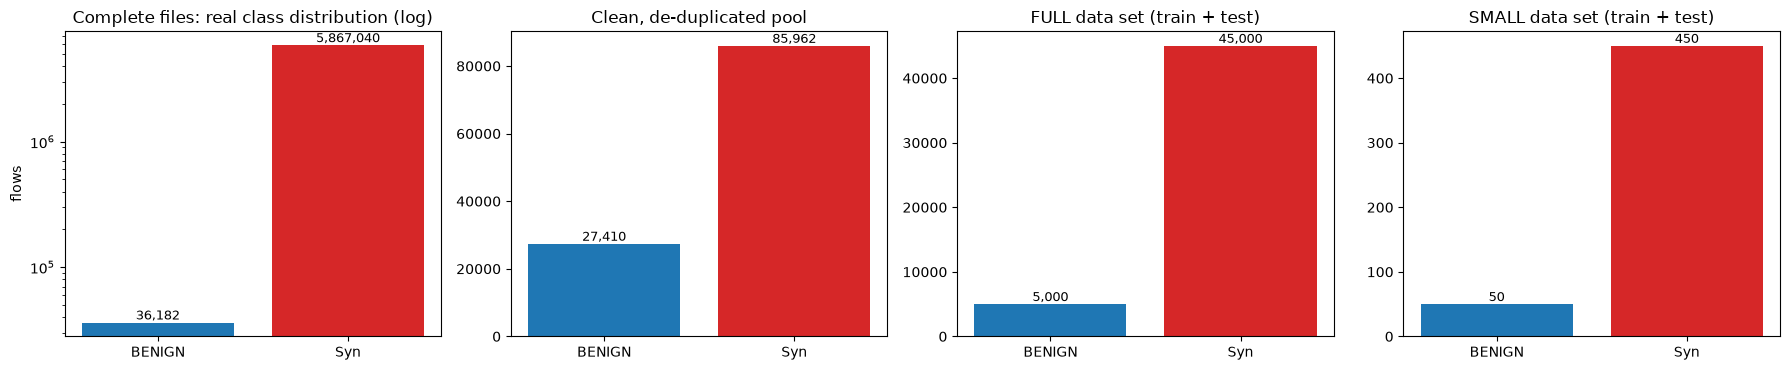

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
ben_total = sum(c.get("BENIGN", 0) for c in full_counts.values()); syn_total = sum(c.get("Syn", 0) for c in full_counts.values())
axes[0].bar(["BENIGN", "Syn"], [ben_total, syn_total], color=["tab:blue", "tab:red"])
axes[0].set_yscale("log"); axes[0].set_title("Complete files: real class distribution (log)")
for i, v in enumerate([ben_total, syn_total]): axes[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
axes[0].set_ylabel("flows")
counts_pool = [int((y_all == 0).sum()), int((y_all == 1).sum())]
axes[1].bar(["BENIGN", "Syn"], counts_pool, color=["tab:blue", "tab:red"]); axes[1].set_title("Clean, de-duplicated pool")
for i, v in enumerate(counts_pool): axes[1].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
for ax, d, nm in [(axes[2], full, "FULL data set (train + test)"), (axes[3], small, "SMALL data set (train + test)")]:
    cnt = [int((d["y_tr"] == k).sum() + (d["y_te"] == k).sum()) for k in (0, 1)]
    ax.bar(["BENIGN", "Syn"], cnt, color=["tab:blue", "tab:red"]); ax.set_title(nm)
    for i, v in enumerate(cnt): ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

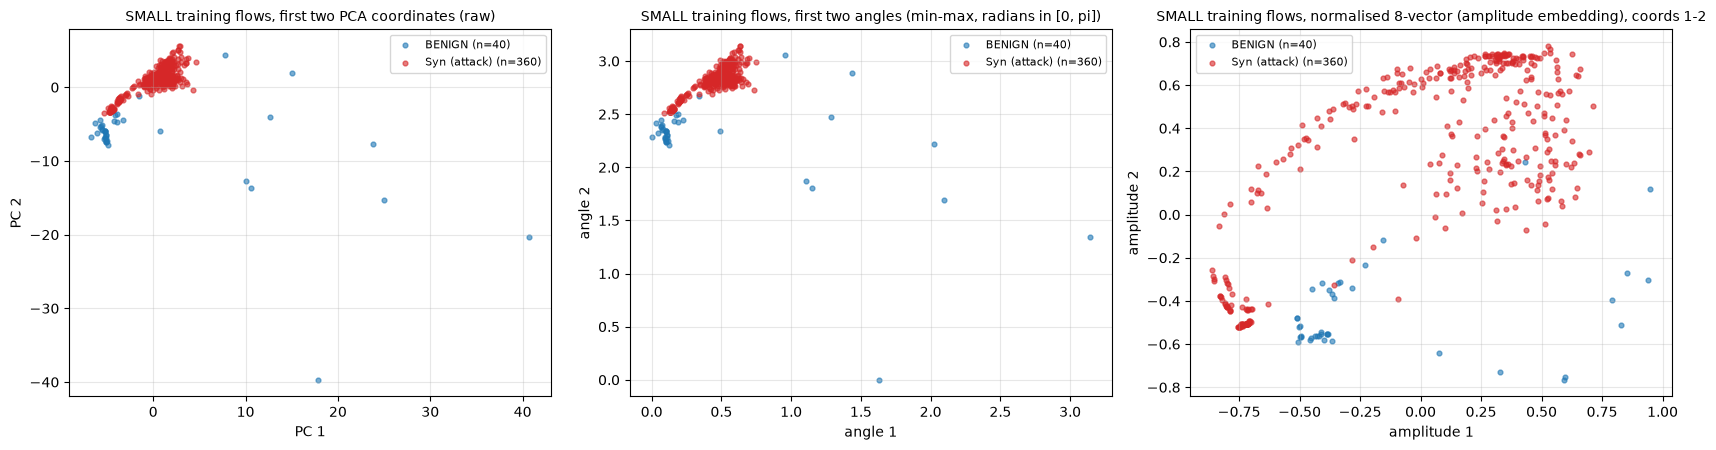

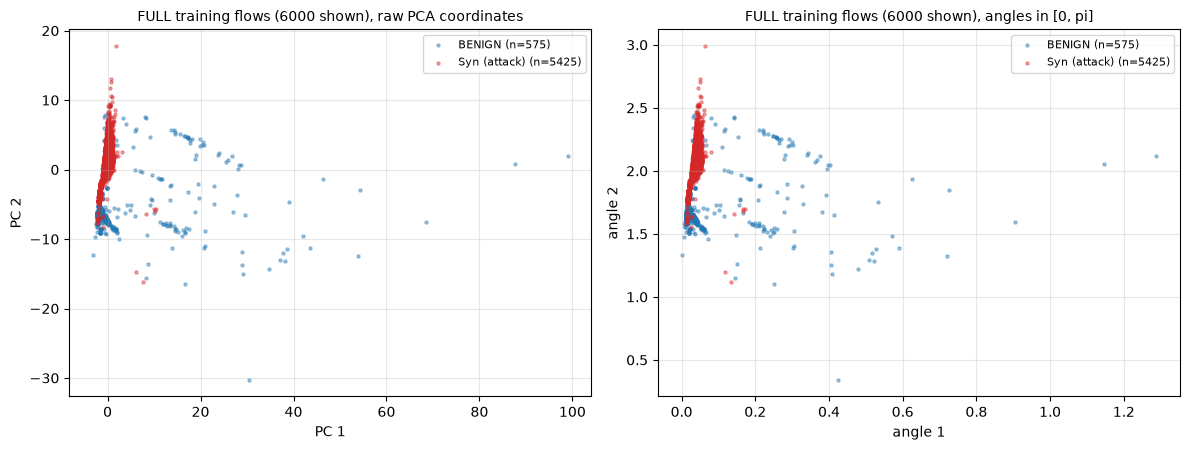

PCA variance explained per component (small): [0.253 0.212 0.082 0.065 0.06  0.058 0.044 0.035] total 0.808
PCA variance explained per component (full) : [0.229 0.179 0.082 0.056 0.053 0.047 0.042 0.034] total 0.722


In [10]:
# 2-D scatter of REAL training flows coloured by their ground-truth label.
# Left: raw PCA coordinates (PCA fitted on the standardised training split). Middle: the same two coordinates min-max scaled
# to [0, pi], i.e. the first two rotation angles of angle embedding / ZZ map. Right: the direction of the 8-vector, which is
# what amplitude embedding keeps (the vector is normalised), shown through its first two normalised coordinates.
colors = {0: "tab:blue", 1: "tab:red"}
def scat(ax, pts, y, title, xl, yl, s=12, alpha=0.6):
    for k in (0, 1):
        m = y == k
        ax.scatter(pts[m, 0], pts[m, 1], s=s, alpha=alpha, c=colors[k], label=f"{CLASS_NAMES[k]} (n={m.sum()})")
    ax.set_title(title, fontsize=10); ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend(fontsize=8); ax.grid(alpha=0.3)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
scat(axes[0], small["Z_tr"], small["y_tr"], "SMALL training flows, first two PCA coordinates (raw)", "PC 1", "PC 2")
scat(axes[1], small["A_tr"], small["y_tr"], "SMALL training flows, first two angles (min-max, radians in [0, pi])", "angle 1", "angle 2")
nz = small["Z_tr"] / np.linalg.norm(small["Z_tr"], axis=1, keepdims=True)
scat(axes[2], nz, small["y_tr"], "SMALL training flows, normalised 8-vector (amplitude embedding), coords 1-2", "amplitude 1", "amplitude 2")
plt.tight_layout(); plt.show()

sub = np.random.default_rng(SEED).choice(len(full["y_tr"]), min(6000, len(full["y_tr"])), replace=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
scat(axes[0], full["Z_tr"][sub], full["y_tr"][sub], "FULL training flows (6000 shown), raw PCA coordinates", "PC 1", "PC 2", s=5, alpha=0.4)
scat(axes[1], full["A_tr"][sub], full["y_tr"][sub], "FULL training flows (6000 shown), angles in [0, pi]", "angle 1", "angle 2", s=5, alpha=0.4)
plt.tight_layout(); plt.show()
print("PCA variance explained per component (small):", small["pca"].explained_variance_ratio_.round(3), "total", small["pca"].explained_variance_ratio_.sum().round(3))
print("PCA variance explained per component (full) :", full["pca"].explained_variance_ratio_.round(3), "total", full["pca"].explained_variance_ratio_.sum().round(3))

## 6. Classical models on the full data set

### 6.1 Metrics and report layout

The paper prints, for each model, a confusion matrix (rows = real class, columns = predicted class, `Syn` first) and a classification report with precision, recall, F1 and support per class. The helper below produces both in that layout. Remember: **precision** = of the flows the model calls BENIGN, how many really are; **recall** = of all real BENIGN flows, how many the model finds; F1 is their harmonic mean. In our coding Syn is the positive class, so the Syn row of the report is the attack-detection quality and the BENIGN row measures false alarms.

In [11]:
LABELS = [1, 0]                       # Syn first, as in the paper's tables
NAMES = ["Syn", "BENIGN"]

def report(y_true, y_pred, score=None):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1], zero_division=0)
    w = np.array([s[0], s[1]]) / s.sum()
    out = dict(accuracy=accuracy_score(y_true, y_pred),
               p_benign=p[0], r_benign=r[0], f1_benign=f[0], p_syn=p[1], r_syn=r[1], f1_syn=f[1],
               f1_macro=f.mean(), f1_weighted=float((f * w).sum()))
    if score is not None:
        out["auc"] = roc_auc_score(y_true, score)
    return out

def paper_tables(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)
    print(title)
    display(pd.DataFrame(cm, index=pd.MultiIndex.from_product([["Real"], NAMES]),
                         columns=pd.MultiIndex.from_product([["Predicted"], NAMES])))
    rep = pd.DataFrame(classification_report(y_true, y_pred, labels=LABELS, target_names=NAMES,
                                             output_dict=True, zero_division=0)).T
    rep.loc["accuracy", ["precision", "recall"]] = np.nan
    rep.loc["accuracy", "support"] = len(y_true)
    rep["support"] = rep["support"].astype(int)
    display(rep.round(2).fillna(""))
    return cm

results = {}          # name -> metrics of the paper-like run on the FULL (classical) or SMALL (quantum) test set
times = {}
preds = {}
scores_ = {}

### 6.2 Classical SVM with an RBF kernel (paper Tables 1 and 2)

One model, RBF kernel, no GPU. The inputs are the 8 PCA components of the full data set (scaled to [0, pi] like the quantum angles, so that all models see the same numbers; an RBF SVM does not care about the scale choice). The SVM is trained on 40 000 flows, which takes about half a minute.

In [12]:
t0 = time.perf_counter()
svm_full = SVC(kernel="rbf", C=SVM_C, gamma="scale", random_state=SEED).fit(full["A_tr"], full["y_tr"])
preds["SVM RBF (full)"] = svm_full.predict(full["A_te"])
scores_["SVM RBF (full)"] = svm_full.decision_function(full["A_te"])
times["SVM RBF (full)"] = seconds_since(t0)
results["SVM RBF (full)"] = report(full["y_te"], preds["SVM RBF (full)"], scores_["SVM RBF (full)"])
paper_tables(full["y_te"], preds["SVM RBF (full)"], "Classical SVM, full data set (compare with paper Tables 1 and 2)")
print(f"train + predict time {times['SVM RBF (full)']:.1f} s")

Classical SVM, full data set (compare with paper Tables 1 and 2)


Predicted       
                  Syn BENIGN
Real Syn         8957     43
     BENIGN        88    912

,precision,recall,f1-score,support
Syn,0.99,1.0,0.99,9000
BENIGN,0.95,0.91,0.93,1000
accuracy,,,0.99,10000
macro avg,0.97,0.95,0.96,10000
weighted avg,0.99,0.99,0.99,10000


train + predict time 45.1 s


### 6.3 Classical neural network 8x8x16x8x1 (paper Figures 2 and 3, Tables 3 and 4)

A fully connected network with 8 inputs (one per PCA component), hidden layers of 8, 16 and 8 neurons and one output neuron (attack probability). We train it epoch by epoch and record the training loss and the validation loss, which is what the paper's Figure 2 shows, then draw the ROC curve (paper Figure 3). 10 % of the training flows are held out for the validation loss (the test flows are never used for training or for choosing anything).

Network shape (inputs, hidden..., outputs): [8, 8, 16, 8, 1] | epochs: 100


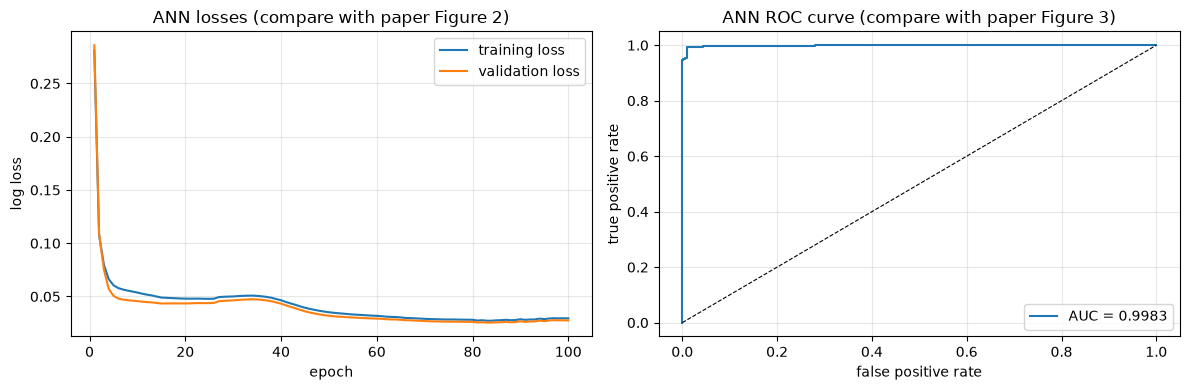

ANN, full data set (compare with paper Tables 3 and 4)


Predicted       
                  Syn BENIGN
Real Syn         8947     53
     BENIGN        24    976

,precision,recall,f1-score,support
Syn,1.0,0.99,1.00,9000
BENIGN,0.95,0.98,0.96,1000
accuracy,,,0.99,10000
macro avg,0.97,0.99,0.98,10000
weighted avg,0.99,0.99,0.99,10000


training time 179.5 s


In [13]:
X_fit, X_val, y_fit, y_val = train_test_split(full["A_tr"], full["y_tr"], test_size=0.10, stratify=full["y_tr"], random_state=SEED)
ann = MLPClassifier(hidden_layer_sizes=(8, 16, 8), activation="relu", solver="adam", batch_size=64,
                    learning_rate_init=1e-3, random_state=SEED)
t0 = time.perf_counter()
train_loss, val_loss = [], []
sub_fit = np.random.default_rng(SEED).choice(len(X_fit), min(8000, len(X_fit)), replace=False)
for epoch in range(ANN_EPOCHS):
    ann.partial_fit(X_fit, y_fit, classes=[0, 1])
    train_loss.append(log_loss(y_fit[sub_fit], ann.predict_proba(X_fit[sub_fit])[:, 1], labels=[0, 1]))
    val_loss.append(log_loss(y_val, ann.predict_proba(X_val)[:, 1], labels=[0, 1]))
preds["ANN 8-8-16-8-1 (full)"] = ann.predict(full["A_te"])
scores_["ANN 8-8-16-8-1 (full)"] = ann.predict_proba(full["A_te"])[:, 1]
times["ANN 8-8-16-8-1 (full)"] = seconds_since(t0)
results["ANN 8-8-16-8-1 (full)"] = report(full["y_te"], preds["ANN 8-8-16-8-1 (full)"], scores_["ANN 8-8-16-8-1 (full)"])
print("Network shape (inputs, hidden..., outputs):", [full["A_tr"].shape[1], *ann.hidden_layer_sizes, 1], "| epochs:", ANN_EPOCHS)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, ANN_EPOCHS + 1), train_loss, label="training loss"); axes[0].plot(range(1, ANN_EPOCHS + 1), val_loss, label="validation loss")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("log loss"); axes[0].set_title("ANN losses (compare with paper Figure 2)"); axes[0].legend(); axes[0].grid(alpha=0.3)
fpr, tpr, _ = roc_curve(full["y_te"], scores_["ANN 8-8-16-8-1 (full)"])
axes[1].plot(fpr, tpr, label=f"AUC = {results['ANN 8-8-16-8-1 (full)']['auc']:.4f}"); axes[1].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate"); axes[1].set_title("ANN ROC curve (compare with paper Figure 3)"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
paper_tables(full["y_te"], preds["ANN 8-8-16-8-1 (full)"], "ANN, full data set (compare with paper Tables 3 and 4)")
print(f"training time {times['ANN 8-8-16-8-1 (full)']:.1f} s")

## 7. From the kernel SVM to the quantum SVM

An SVM only needs one thing from the data: how similar each pair of flows is. That similarity is the **kernel** K(x, y). A QSVM keeps the classical SVM optimiser and replaces the kernel by one computed with a quantum circuit:

1. a **feature map** circuit U(x) loads a flow x (8 numbers) into the state |phi(x)> = U(x)|0...0> of some qubits;
2. the kernel is the overlap of two such states, **K(x, y) = |<phi(x)|phi(y)>|^2**: 1 for identical states, close to 0 for very different ones. On a quantum computer this is measured by running U(x), then the inverse of U(y), and counting how often all qubits return to 0;
3. the matrix of all pairs of training flows goes to the ordinary SVM solver (`SVC(kernel="precomputed")`), and the prediction for a new flow uses its kernel values against the training flows.

The three ways to load the data are the paper's "feature maps":

* **Angle embedding** (8 qubits): feature k becomes the rotation angle of qubit k (`RX(x_k)`). No gate links two qubits, so the state is a product state and the kernel factorises: K = product over k of cos^2((x_k - y_k)/2).
* **Amplitude embedding** (3 qubits): the 8 numbers become the 2^3 = 8 amplitudes of the state (after normalising the vector to length 1), so K(x, y) = (x . y)^2 / (|x|^2 |y|^2): only the *direction* of the vector counts.
* **ZZ feature map** (8 qubits): Hadamards, one phase per feature, and between neighbouring qubits a CNOT - phase - CNOT block whose phase depends on the *product* of two features, repeated twice. This entangles the qubits and encodes feature interactions; the circuit is much deeper.

The paper says it used PennyLane's kernel utilities. We write the three feature maps as PennyLane functions and build one circuit per kernel entry with them; all of it is simulated exactly.

In [14]:
def angle_map(x, wires):
    # angle embedding: RX(x_k) on qubit k, no entangling gates
    qml.AngleEmbedding(x, wires=wires, rotation="X")

def amp_map(x, wires):
    # amplitude embedding: the 8 (normalised) numbers are the amplitudes of 3 qubits
    qml.AmplitudeEmbedding(x, wires=wires, normalize=True)

def zz_map(x, wires, reps=2):
    # CHOICE: ZZ feature map of Havlicek et al., reps=2, linear entanglement (neighbouring qubits only)
    n = len(wires)
    for _ in range(reps):
        for w in wires:
            qml.Hadamard(wires=w)
        for i, w in enumerate(wires):
            qml.PhaseShift(2 * x[..., i], wires=w)
        for i in range(n - 1):
            qml.CNOT(wires=[wires[i], wires[i + 1]])
            qml.PhaseShift(2 * (np.pi - x[..., i]) * (np.pi - x[..., i + 1]), wires=wires[i + 1])
            qml.CNOT(wires=[wires[i], wires[i + 1]])

def make_circuits(feature_map, n_wires):
    dev = qml.device("default.qubit", wires=n_wires)
    @qml.qnode(dev)
    def kernel_circuit(x1, x2):
        # the 'overlap test': encode x1, then undo the encoding of x2; P(all zeros) = |<phi(x2)|phi(x1)>|^2
        feature_map(x1, wires=range(n_wires))
        qml.adjoint(feature_map)(x2, wires=range(n_wires))
        return qml.probs(wires=range(n_wires))
    @qml.qnode(dev)
    def state_circuit(x):
        feature_map(x, wires=range(n_wires))
        return qml.state()
    return kernel_circuit, state_circuit

MAPS = {
    "angle":     dict(label="QSVM angle embedding",     fm=angle_map, n_wires=8, input="A", tunable=True),
    "amplitude": dict(label="QSVM amplitude embedding", fm=amp_map,   n_wires=3, input="Z", tunable=False),
    "zz":        dict(label="QSVM ZZ feature map",      fm=zz_map,    n_wires=8, input="A", tunable=True),
}
for key, m in MAPS.items():
    m["kernel_circuit"], m["state_circuit"] = make_circuits(m["fm"], m["n_wires"])
    print(f"{m['label']:26s} qubits: {m['n_wires']}")

QSVM angle embedding       qubits: 8
QSVM amplitude embedding   qubits: 3
QSVM ZZ feature map        qubits: 8


## 8. Quantum Circuit Architecture

The three circuits below are the **kernel circuits that PennyLane executes** for one pair of flows (x1, x2): the feature map U(x1) followed by the inverse of U(x2), then a measurement of all qubits. They are drawn with `qml.draw_mpl(..., level="device")`, i.e. as the gates the simulator really receives. The example flows are the first two training flows of the small data set after preprocessing.

What to look for:

* **Encoding**: every data value is a rotation angle (`RX`, or `Rphi` phase shifts in the ZZ map) or, for amplitude embedding, the amplitudes of the initial state (`|Psi>`), followed in the inverse half by the gates that undo it.
* **Trainable parameters**: none. In a kernel method the circuit only encodes data; the only training is the classical SVM on the kernel matrix. The tables report the number of *data-encoding* parameters instead.
* **Entanglement**: none for angle embedding, CNOT chains for the ZZ map, and the CNOTs of the state-preparation routine for amplitude embedding.
* **Measurement**: the probabilities of all basis states; the kernel is the probability of the all-zeros outcome.

**Assumptions where the paper gives no circuit details.** The paper shows only a picture of the ZZ kernel (its Figure 4), which cannot be read in the text version of the paper. We therefore use the standard ZZ feature map with two repetitions and linear entanglement, and `RX` rotations for the angle embedding (PennyLane's default rotation). Amplitude embedding is PennyLane's `AmplitudeEmbedding` with normalisation; its inverse is decomposed by PennyLane into the RY rotations and CNOTs shown in the drawing.

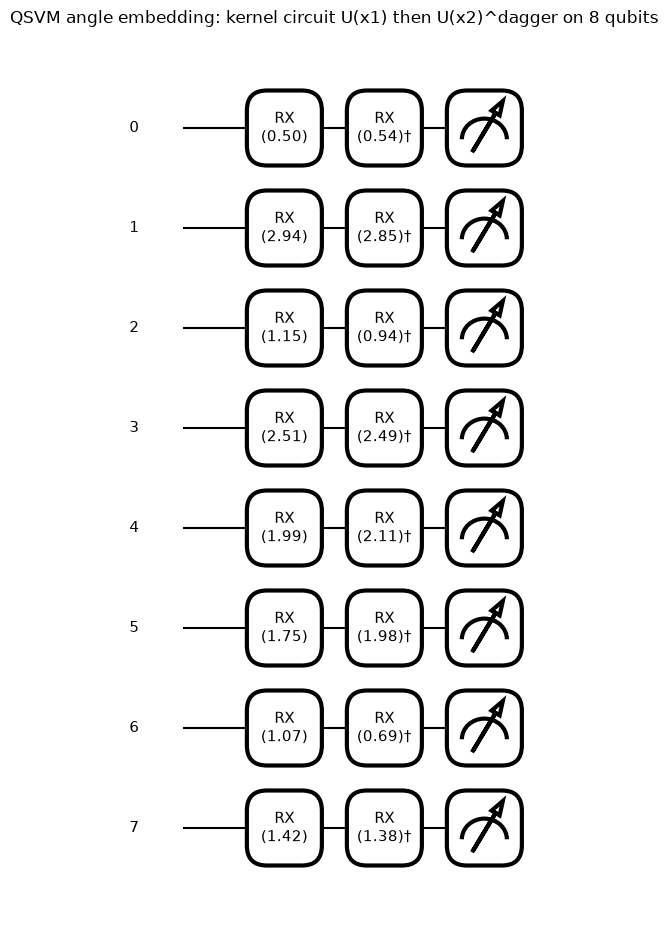

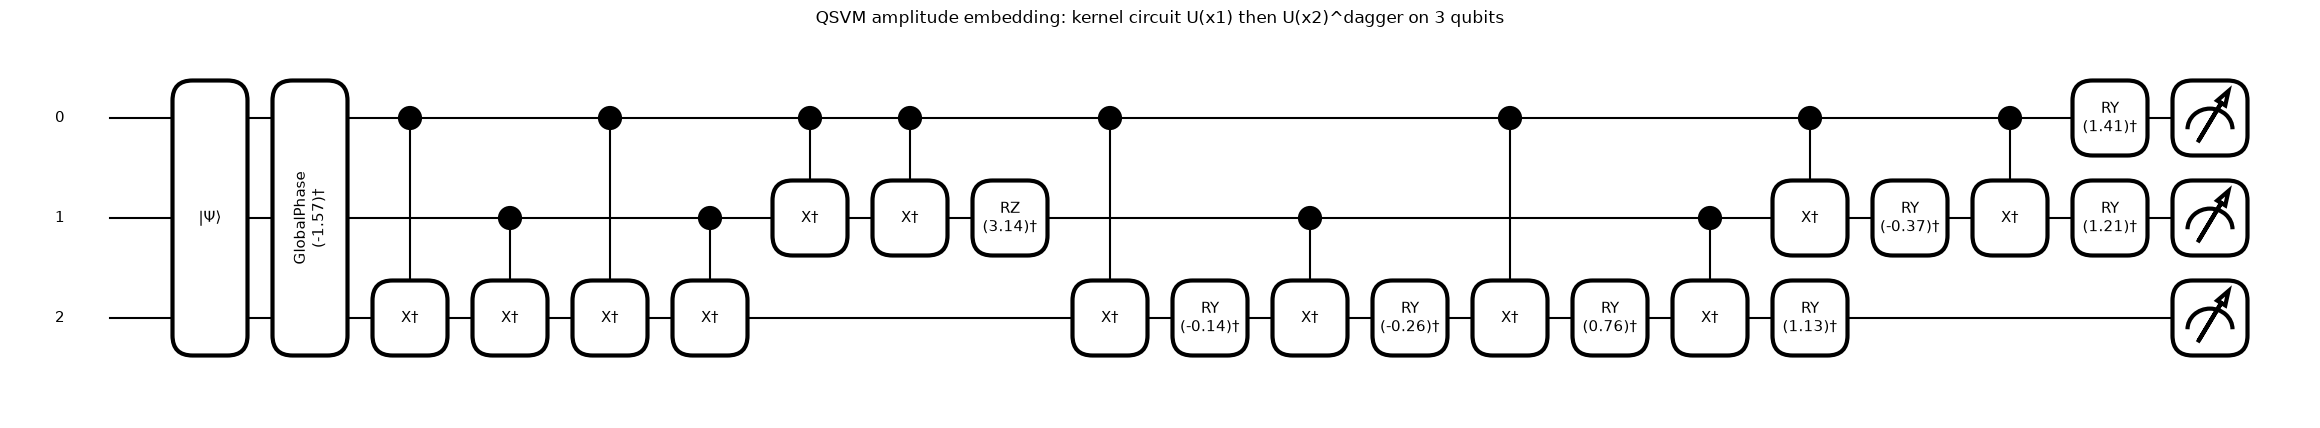

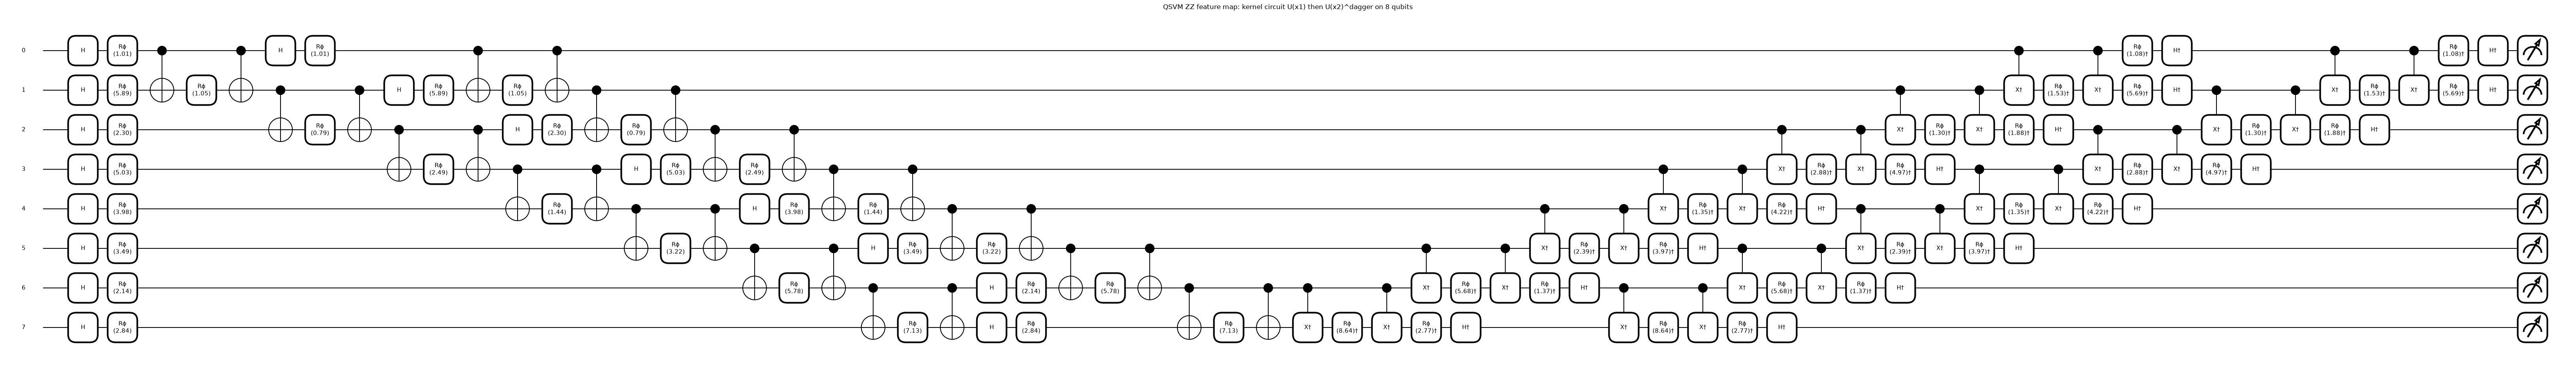

,qubits,depth,total_gates,trainable_parameters,data_parameters_per_flow
model,,,,,
QSVM angle embedding,8,2,16,0,8
QSVM amplitude embedding,3,19,22,0,8
QSVM ZZ feature map,8,62,148,0,8


QSVM angle embedding       gates: {'RX': 8, 'Adjoint(RX)': 8}
QSVM amplitude embedding   gates: {'AmplitudeEmbedding': 1, 'Adjoint(GlobalPhase)': 1, 'Adjoint(CNOT)': 12, 'Adjoint(RZ)': 1, 'Adjoint(RY)': 7}
QSVM ZZ feature map        gates: {'Hadamard': 16, 'PhaseShift': 30, 'CNOT': 28, 'Adjoint(CNOT)': 28, 'Adjoint(PhaseShift)': 30, 'Adjoint(Hadamard)': 16}


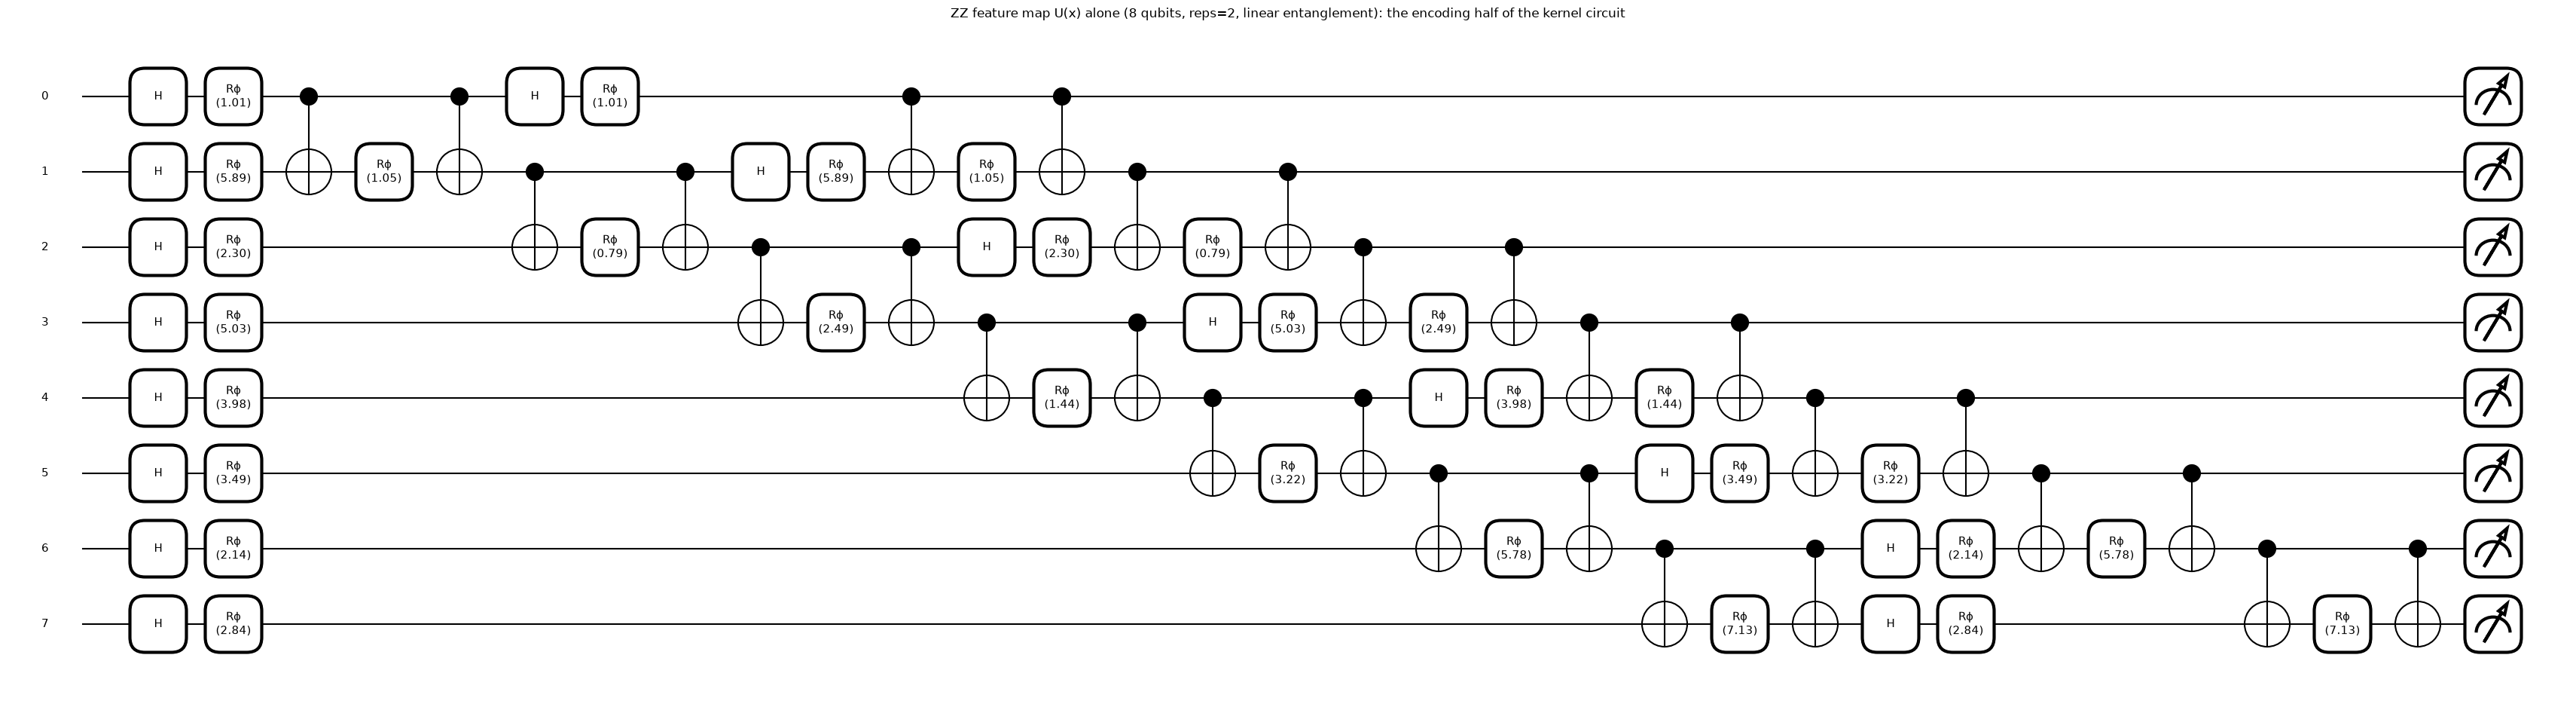

ZZ feature map alone: qubits 8, depth 31 , gates 74 , trainable parameters 0, data parameters 8


In [15]:
x1, x2 = small["A_tr"][0], small["A_tr"][1]
z1, z2 = small["Z_tr"][0], small["Z_tr"][1]
arch_rows = []
for key, m in MAPS.items():
    a1, a2 = (x1, x2) if m["input"] == "A" else (z1, z2)
    fig, ax = qml.draw_mpl(m["kernel_circuit"], level="device", decimals=2, fontsize=11)(a1, a2)
    fig.suptitle(f"{m['label']}: kernel circuit U(x1) then U(x2)^dagger on {m['n_wires']} qubits", y=1.02, fontsize=12)
    plt.show()
    sp = qml.specs(m["kernel_circuit"], level="device")(a1, a2)
    gates = dict(sp.resources.gate_types)
    arch_rows.append(dict(model=m["label"], qubits=m["n_wires"], depth=sp.resources.depth, total_gates=sp.resources.num_gates,
                          trainable_parameters=0, data_parameters_per_flow=int(len(a1)), gate_counts=gates))
display(pd.DataFrame(arch_rows).drop(columns="gate_counts").set_index("model"))
for r_ in arch_rows:
    print(f"{r_['model']:26s} gates: {r_['gate_counts']}")

# the ZZ kernel circuit is very wide (U(x1) followed by its mirror image U(x2)^dagger); here is the feature map U(x) alone, which is
# the left half of that drawing, at a readable size
fig, ax = qml.draw_mpl(MAPS["zz"]["state_circuit"], level="device", decimals=2, fontsize=11)(x1)
fig.suptitle("ZZ feature map U(x) alone (8 qubits, reps=2, linear entanglement): the encoding half of the kernel circuit", y=1.02, fontsize=12)
plt.show()
spf = qml.specs(MAPS["zz"]["state_circuit"], level="device")(x1)
print("ZZ feature map alone: qubits 8, depth", spf.resources.depth, ", gates", spf.resources.num_gates, ", trainable parameters 0, data parameters 8")

### The kernels: exact states, checked against the executed circuits

Running one circuit per pair is slow for hundreds of flows (400 x 400 pairs for the training matrix). The kernel is a plain overlap of two state vectors, so we run the **feature map once per flow** (`qml.state()` on the same gates), keep the state vectors, and get the whole matrix as `|S_a S_b^dagger|^2`. The next cell proves that this shortcut equals the executed overlap-test circuit above (and PennyLane's own `qml.kernels.kernel_matrix` helper) on real flows, for all three maps.

In [16]:
def states_of(m, X, chunk=250):
    # state vectors of all rows of X (PennyLane evaluates a whole batch of flows in one call)
    return np.vstack([m["state_circuit"](X[i:i + chunk]) for i in range(0, len(X), chunk)])

def kernel_from_states(Sa, Sb):
    return np.abs(Sa.conj() @ Sb.T) ** 2

# closed forms for the two maps that have one (extra independent check)
def angle_kernel_closed(XA, XB):  return np.prod(np.cos((XA[:, None, :] - XB[None, :, :]) / 2) ** 2, axis=2)
def amp_kernel_closed(XA, XB):
    nA = XA / np.linalg.norm(XA, axis=1, keepdims=True); nB = XB / np.linalg.norm(XB, axis=1, keepdims=True)
    return (nA @ nB.T) ** 2

r = np.random.default_rng(SEED)
check_rows = []
for key, m in MAPS.items():
    base_tr = small["A_tr"] if m["input"] == "A" else small["Z_tr"]
    base_te = small["A_te"] if m["input"] == "A" else small["Z_te"]
    i = r.choice(len(base_tr), 60, replace=False); j = r.choice(len(base_te), 60, replace=False)
    P, Q = base_tr[i], base_te[j]
    k_circuit = m["kernel_circuit"](P, Q)[:, 0]                          # executed overlap test, 60 pairs in one batch
    Sp, Sq = states_of(m, P), states_of(m, Q)
    k_states = np.abs(np.sum(Sp.conj() * Sq, axis=1)) ** 2
    ok_circuit = np.allclose(k_circuit, k_states, atol=1e-9)
    # PennyLane's own helper on a 5 x 5 block
    km = qml.kernels.kernel_matrix(P[:5], Q[:5], lambda a, b: m["kernel_circuit"](a, b)[0])
    ok_helper = np.allclose(km, kernel_from_states(Sp[:5], Sq[:5]), atol=1e-9)
    closed = {"angle": angle_kernel_closed, "amplitude": amp_kernel_closed}.get(key)
    ok_closed = None if closed is None else np.allclose(closed(P[:5], Q[:5]), kernel_from_states(Sp[:5], Sq[:5]), atol=1e-9)
    check_rows.append(dict(map=m["label"], circuit_vs_states=ok_circuit, kernel_matrix_helper_vs_states=ok_helper, closed_form_vs_states=ok_closed,
                           mean_kernel_value=float(k_states.mean())))
    assert ok_circuit and ok_helper and (ok_closed in (None, True)), f"kernel mismatch for {key}"
display(pd.DataFrame(check_rows).set_index("map"))

,circuit_vs_states,kernel_matrix_helper_vs_states,closed_form_vs_states,mean_kernel_value
map,,,,
QSVM angle embedding,True,True,True,0.794605
QSVM amplitude embedding,True,True,True,0.338193
QSVM ZZ feature map,True,True,None,0.249078


### Kernel bandwidth: how far apart the encoded states should be

If almost every pair of different flows has a kernel value near 0 (see `mean_kernel_value` above), the SVM treats every flow as unlike every other flow and can only memorise the training data. A simple remedy is to multiply all angles by a **bandwidth** factor before they enter the circuit; a smaller factor keeps the states closer together. The paper does not mention this, so it is our addition (`# CHOICE:`). It is chosen **on a validation part of the training flows only** (70 % fit, 30 % validation, macro-F1 as the score because the BENIGN class is small); the test flows never take part. Amplitude embedding normalises the vector, so a scale factor has no effect and is not tuned.

In [17]:
def pick_input(m, d, part):
    return d[("A_" if m["input"] == "A" else "Z_") + part]

def choose_bandwidth(m, X_part, y_part, seed):
    if not m["tunable"]:
        return 1.0, {}
    X_fit, X_val, y_fit, y_val = train_test_split(X_part, y_part, test_size=0.3, stratify=y_part, random_state=seed)
    scores = {}
    for bw in BANDWIDTH_GRID:
        S_fit, S_val = states_of(m, X_fit * bw), states_of(m, X_val * bw)
        clf = SVC(kernel="precomputed", C=SVM_C).fit(kernel_from_states(S_fit, S_fit), y_fit)
        scores[bw] = f1_score(y_val, clf.predict(kernel_from_states(S_val, S_fit)), average="macro")
    best = max(scores, key=lambda b: (round(scores[b], 6), -abs(np.log(b))))     # ties: prefer bandwidth closest to 1
    return best, scores

def run_qsvm(key, d, seed):
    m = MAPS[key]
    X_tr, X_te = pick_input(m, d, "tr"), pick_input(m, d, "te")
    t0 = time.perf_counter()
    bw, val_scores = choose_bandwidth(m, X_tr, d["y_tr"], seed)
    S_tr, S_te = states_of(m, X_tr * bw), states_of(m, X_te * bw)
    K_tr, K_te = kernel_from_states(S_tr, S_tr), kernel_from_states(S_te, S_tr)
    clf = SVC(kernel="precomputed", C=SVM_C).fit(K_tr, d["y_tr"])
    pred, score = clf.predict(K_te), clf.decision_function(K_te)
    return dict(bandwidth=bw, val_scores=val_scores, pred=pred, score=score, time=seconds_since(t0),
                mean_offdiag=float((K_tr.sum() - np.trace(K_tr)) / (K_tr.size - len(K_tr))), K_tr=K_tr, **report(d["y_te"], pred, score))
print("Helpers ready.")

Helpers ready.


## 9. Training the three quantum SVMs (paper Tables 5 to 10 and Figures 5 to 7)

Draw 0 is the single "paper-like" run: one small data set (400 training and 100 test flows, 90 Syn + 10 BENIGN in the test set), one QSVM per feature map. We print the confusion matrix and classification report in the paper's layout and draw the ROC curve of each model. Because the test set has only 10 BENIGN flows, a single misclassified flow moves the BENIGN recall by 10 points, so Section 10 repeats the experiment on several random draws.

In [18]:
quantum = {}
for key in MAPS:
    res = run_qsvm(key, small, SEED)
    quantum[key] = res
    name = MAPS[key]["label"] + " (small)"
    preds[name], scores_[name], times[name] = res["pred"], res["score"], res["time"]
    results[name] = {k: res[k] for k in ["accuracy", "p_benign", "r_benign", "f1_benign", "p_syn", "r_syn", "f1_syn", "f1_macro", "f1_weighted", "auc"]}
    print(f"bandwidth chosen on validation: {res['bandwidth']}  (validation macro-F1: { {k: round(v, 3) for k, v in res['val_scores'].items()} })")
    print(f"mean off-diagonal training kernel value: {res['mean_offdiag']:.4f} | time (states + kernels + SVM + prediction): {res['time']:.1f} s")
    paper_tables(small["y_te"], res["pred"], f"{MAPS[key]['label']}, small data set")
    print()

bandwidth chosen on validation: 2.0  (validation macro-F1: {0.05: 0.474, 0.1: 0.474, 0.25: 0.474, 0.5: 0.857, 1.0: 0.922, 2.0: 0.976})
mean off-diagonal training kernel value: 0.5771 | time (states + kernels + SVM + prediction): 1.2 s
QSVM angle embedding, small data set


Predicted       
                  Syn BENIGN
Real Syn           90      0
     BENIGN         1      9

,precision,recall,f1-score,support
Syn,0.99,1.0,0.99,90
BENIGN,1.0,0.9,0.95,10
accuracy,,,0.99,100
macro avg,0.99,0.95,0.97,100
weighted avg,0.99,0.99,0.99,100


bandwidth chosen on validation: 1.0  (validation macro-F1: {})
mean off-diagonal training kernel value: 0.3079 | time (states + kernels + SVM + prediction): 0.1 s
QSVM amplitude embedding, small data set


Predicted       
                  Syn BENIGN
Real Syn           90      0
     BENIGN         0     10

,precision,recall,f1-score,support
Syn,1.0,1.0,1.0,90
BENIGN,1.0,1.0,1.0,10
accuracy,,,1.0,100
macro avg,1.0,1.0,1.0,100
weighted avg,1.0,1.0,1.0,100


bandwidth chosen on validation: 1.0  (validation macro-F1: {0.05: 0.82, 0.1: 0.891, 0.25: 0.976, 0.5: 0.976, 1.0: 1.0, 2.0: 0.68})
mean off-diagonal training kernel value: 0.2258 | time (states + kernels + SVM + prediction): 4.1 s
QSVM ZZ feature map, small data set


Predicted       
                  Syn BENIGN
Real Syn           90      0
     BENIGN         1      9

,precision,recall,f1-score,support
Syn,0.99,1.0,0.99,90
BENIGN,1.0,0.9,0.95,10
accuracy,,,0.99,100
macro avg,0.99,0.95,0.97,100
weighted avg,0.99,0.99,0.99,100


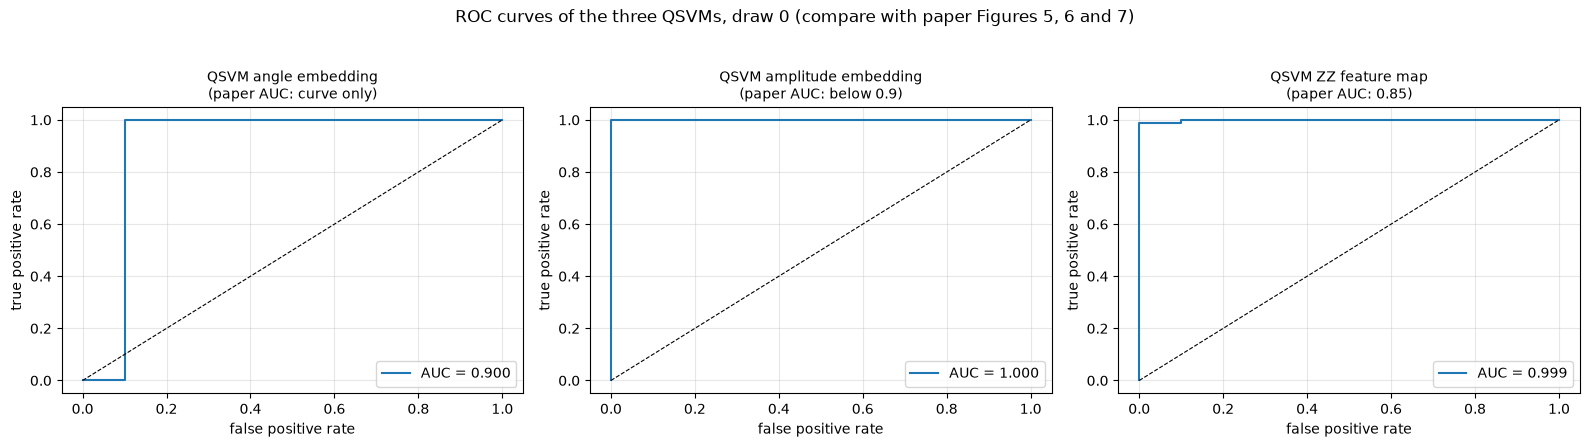

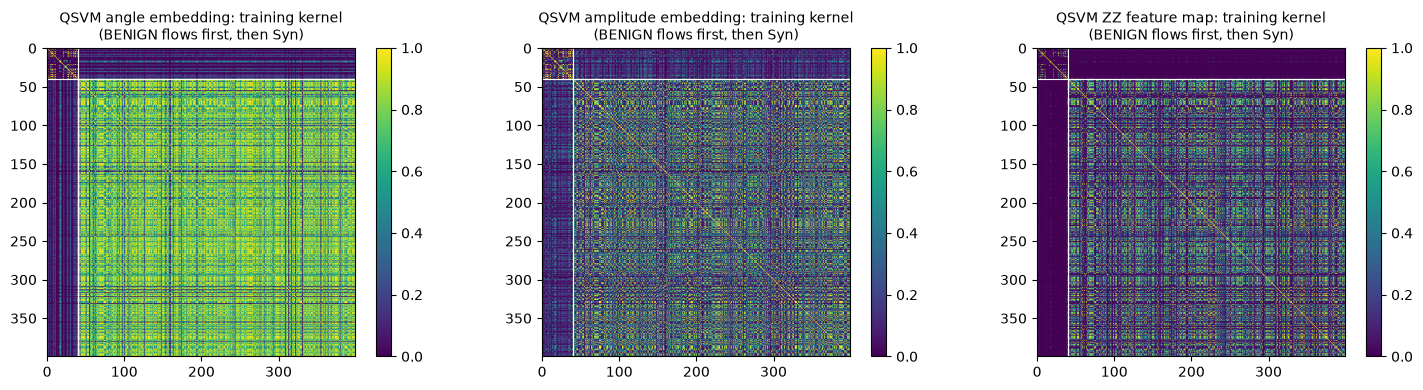

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
paper_auc = {"angle": None, "amplitude": "below 0.9", "zz": "0.85"}
for ax, key in zip(axes, MAPS):
    res = quantum[key]
    fpr, tpr, _ = roc_curve(small["y_te"], res["score"])
    ax.plot(fpr, tpr, label=f"AUC = {res['auc']:.3f}"); ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_title(f"{MAPS[key]['label']}\n(paper AUC: {paper_auc[key] or 'curve only'})", fontsize=10)
    ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate"); ax.legend(loc="lower right"); ax.grid(alpha=0.3)
plt.suptitle("ROC curves of the three QSVMs, draw 0 (compare with paper Figures 5, 6 and 7)", y=1.03)
plt.tight_layout(); plt.show()

# kernel matrices of the three maps: do flows of the same class look alike to the quantum circuit?
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
order = np.argsort(small["y_tr"], kind="stable")
for ax, key in zip(axes, MAPS):
    K = quantum[key]["K_tr"][np.ix_(order, order)]
    im = ax.imshow(K, cmap="viridis", vmin=0, vmax=1)
    nb = int((small["y_tr"] == 0).sum()); ax.axhline(nb - 0.5, color="w", lw=0.8); ax.axvline(nb - 0.5, color="w", lw=0.8)
    ax.set_title(f"{MAPS[key]['label']}: training kernel\n(BENIGN flows first, then Syn)", fontsize=10); plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

## 10. Classical models on the same small data set, and repeated random draws

The paper compares its quantum models (small set) with classical models (full set). To compare like with like we also train the classical SVM (RBF) and a random forest on the **same small data sets and the same 8 angles** as the angle and ZZ QSVMs. Then we repeat the whole small experiment on several random draws (new flows, new split, new preprocessing, new bandwidth choice each time) and report mean and standard deviation. Draw 0 is the one shown above.

In [20]:
draw_rows = []
draw0_extra = {}
t_all = time.perf_counter()
for k in range(N_DRAWS):
    seed = SEED + k
    d = small if k == 0 else preprocess(*make_split(N_SMALL, seed))
    row_base = dict(draw=k)
    # classical models on the small data set (same inputs as angle / ZZ QSVM)
    t0 = time.perf_counter(); p = SVC(kernel="rbf", C=SVM_C, gamma="scale").fit(d["A_tr"], d["y_tr"])
    pr, sc = p.predict(d["A_te"]), p.decision_function(d["A_te"]); t = seconds_since(t0)
    draw_rows.append(dict(model="SVM RBF (small)", time=t, **row_base, **report(d["y_te"], pr, sc)))
    t0 = time.perf_counter(); rf = RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=2).fit(d["A_tr"], d["y_tr"])
    pr, sc = rf.predict(d["A_te"]), rf.predict_proba(d["A_te"])[:, 1]; t = seconds_since(t0)
    draw_rows.append(dict(model="RandomForest (small)", time=t, **row_base, **report(d["y_te"], pr, sc)))
    for key in MAPS:
        res = quantum[key] if k == 0 else run_qsvm(key, d, seed)
        draw_rows.append(dict(model=MAPS[key]["label"], time=res["time"], bandwidth=res["bandwidth"], **row_base,
                              **{kk: res[kk] for kk in ["accuracy", "p_benign", "r_benign", "f1_benign", "p_syn", "r_syn", "f1_syn", "f1_macro", "f1_weighted", "auc"]}))
    print(f"draw {k}: " + " | ".join(f"{r['model'].replace('QSVM ', 'Q ')[:18]} acc {r['accuracy']:.2f}" for r in draw_rows[-5:]), flush=True)
draws = pd.DataFrame(draw_rows)
print(f"{N_DRAWS} draws took {seconds_since(t_all) / 60:.1f} min")
cols = ["accuracy", "f1_weighted", "f1_benign", "p_benign", "r_benign", "auc", "time"]
summary = draws.groupby("model")[cols].agg(["mean", "std"]).round(3)
display(summary)

draw 0: SVM RBF (small) acc 0.98 | RandomForest (smal acc 0.99 | Q angle embedding acc 0.99 | Q amplitude embedd acc 1.00 | Q ZZ feature map acc 0.99


draw 1: SVM RBF (small) acc 0.99 | RandomForest (smal acc 0.99 | Q angle embedding acc 0.99 | Q amplitude embedd acc 0.99 | Q ZZ feature map acc 0.99


draw 2: SVM RBF (small) acc 1.00 | RandomForest (smal acc 1.00 | Q angle embedding acc 1.00 | Q amplitude embedd acc 1.00 | Q ZZ feature map acc 1.00


draw 3: SVM RBF (small) acc 0.98 | RandomForest (smal acc 0.98 | Q angle embedding acc 0.98 | Q amplitude embedd acc 0.99 | Q ZZ feature map acc 0.97


draw 4: SVM RBF (small) acc 1.00 | RandomForest (smal acc 1.00 | Q angle embedding acc 1.00 | Q amplitude embedd acc 0.99 | Q ZZ feature map acc 1.00


...

draw 17: SVM RBF (small) acc 0.96 | RandomForest (smal acc 0.97 | Q angle embedding acc 0.96 | Q amplitude embedd acc 0.98 | Q ZZ feature map acc 0.97


draw 18: SVM RBF (small) acc 1.00 | RandomForest (smal acc 1.00 | Q angle embedding acc 1.00 | Q amplitude embedd acc 1.00 | Q ZZ feature map acc 1.00


draw 19: SVM RBF (small) acc 0.97 | RandomForest (smal acc 0.97 | Q angle embedding acc 0.97 | Q amplitude embedd acc 0.97 | Q ZZ feature map acc 0.98


20 draws took 2.7 min


accuracy        f1_weighted        f1_benign         \
                             mean    std        mean    std      mean    std   
model                                                                          
QSVM ZZ feature map         0.986  0.011       0.986  0.012     0.929  0.059   
QSVM amplitude embedding    0.986  0.013       0.986  0.013     0.928  0.070   
QSVM angle embedding        0.988  0.012       0.988  0.012     0.941  0.057   
RandomForest (small)        0.986  0.011       0.986  0.011     0.932  0.057   
SVM RBF (small)             0.986  0.012       0.986  0.012     0.932  0.062   

                         p_benign        r_benign           auc          time  \
                             mean    std     mean    std   mean    std   mean   
model                                                                           
QSVM ZZ feature map         0.934  0.068    0.930  0.086  0.983  0.034  4.516   
QSVM amplitude embedding    0.954  0.053    0.910  0.107  0.985  0.022  0.051   
QSVM angle embedding        0.934  0.068    0.950  0.069  0.977  0.038  1.530   
RandomForest (small)        0.934  0.067    0.935  0.075  0.997  0.003  1.983   
SVM RBF (small)             0.933  0.069    0.935  0.081  0.973  0.040  0.017   

                                 
                            std  
model                            
QSVM ZZ feature map       0.720  
QSVM amplitude embedding  0.017  
QSVM angle embedding      0.370  
RandomForest (small)      0.220  
SVM RBF (small)           0.006

In [21]:
# the same trained models are also tested on a larger, untouched set of flows (2000 flows, 10 % BENIGN) drawn from the pool,
# because 100 test flows (10 BENIGN) cannot separate models that differ by a few points
used = set(small["tr"]) | set(small["te"])
r = np.random.default_rng(SEED + 999)
ben_free = np.array([i for i in np.where(y_all == 0)[0] if i not in used]); syn_free = np.array([i for i in np.where(y_all == 1)[0] if i not in used])
big_idx = np.concatenate([r.choice(ben_free, 200, replace=False), r.choice(syn_free, 1800, replace=False)])
Zb = small["pca"].transform(small["scaler"].transform(X_all[big_idx]))      # transforms fitted on the 400 training flows
Ab = np.clip(small["mm"].transform(Zb), 0, np.pi); yb = y_all[big_idx]
big_rows = {}
for key, m in MAPS.items():
    bw = quantum[key]["bandwidth"]
    Xb = (Ab if m["input"] == "A" else Zb) * bw
    S_tr = states_of(m, pick_input(m, small, "tr") * bw)
    clf = SVC(kernel="precomputed", C=SVM_C).fit(kernel_from_states(S_tr, S_tr), small["y_tr"])
    pr = clf.predict(kernel_from_states(states_of(m, Xb), S_tr))
    big_rows[m["label"]] = report(yb, pr)
svm_s = SVC(kernel="rbf", C=SVM_C, gamma="scale").fit(small["A_tr"], small["y_tr"]); big_rows["SVM RBF (small)"] = report(yb, svm_s.predict(Ab))
big_df = pd.DataFrame(big_rows).T[["accuracy", "f1_weighted", "f1_benign", "p_benign", "r_benign"]].round(3)
print("Models trained on the 400 training flows of draw 0, tested on 2000 untouched flows (200 BENIGN, 1800 Syn):")
display(big_df)

Models trained on the 400 training flows of draw 0, tested on 2000 untouched flows (200 BENIGN, 1800 Syn):


,accuracy,f1_weighted,f1_benign,p_benign,r_benign
QSVM angle embedding,0.990,0.990,0.952,0.959,0.945
QSVM amplitude embedding,0.989,0.989,0.944,0.959,0.930
QSVM ZZ feature map,0.992,0.992,0.960,0.951,0.970
SVM RBF (small),0.988,0.987,0.935,0.968,0.905


## 11. Side-by-side comparison with the paper

The rule for the verdicts: a number is **reproduced** if it is within 0.02 of the paper's value (two accuracy points, or 0.02 F1/precision/recall), **not reached** if it is lower by more, **exceeded** if it is higher by more. For the quantum models the notebook value is the **mean over the random draws** (the paper shows one draw of 100 flows, which carries a sampling error of several points on the BENIGN metrics); the single-draw value is printed next to it.

In [22]:
PAPER = {
    "SVM RBF (full)":         dict(accuracy=0.99, f1_benign=0.96, p_benign=0.93, r_benign=1.00),   # Tables 1-2 (Table 1 typo corrected)
    "ANN 8-8-16-8-1 (full)":  dict(accuracy=0.99, f1_benign=0.97, p_benign=0.95, r_benign=0.99),   # Tables 3-4
    "QSVM angle embedding":   dict(accuracy=0.99, f1_benign=0.95, p_benign=0.91, r_benign=1.00),   # Tables 5-6
    "QSVM amplitude embedding": dict(accuracy=0.97, f1_benign=0.84, p_benign=0.89, r_benign=0.80), # Tables 7-8
    "QSVM ZZ feature map":    dict(accuracy=0.97, f1_benign=0.82, p_benign=1.00, r_benign=0.70),   # Tables 9-10
}
def verdict(nb, paper, tol=0.02):
    d = nb - paper
    return "reproduced" if abs(d) <= tol else ("exceeded" if d > 0 else "not reached")

mean_by_model = draws.groupby("model")[["accuracy", "f1_weighted", "f1_benign", "p_benign", "r_benign", "auc", "time"]].mean()
rows = []
for model, vals in PAPER.items():
    for metric, pv in vals.items():
        if model.endswith("(full)"):
            nb = results[model][metric]; extra = ""
        else:
            nb = mean_by_model.loc[model, metric]; extra = f"{results[model + ' (small)'][metric]:.2f}"
        rows.append(dict(model=model, metric=metric, paper=pv, notebook=round(float(nb), 3), draw0=extra, verdict=verdict(float(nb), pv)))
cmp_df = pd.DataFrame(rows)
display(cmp_df)

,model,metric,paper,notebook,draw0,verdict
0,SVM RBF (full),accuracy,0.99,0.987,,reproduced
1,SVM RBF (full),f1_benign,0.96,0.933,,not reached
2,SVM RBF (full),p_benign,0.93,0.955,,exceeded
3,SVM RBF (full),r_benign,1.00,0.912,,not reached
4,ANN 8-8-16-8-1 (full),accuracy,0.99,0.992,,reproduced
5,ANN 8-8-16-8-1 (full),f1_benign,0.97,0.962,,reproduced
6,ANN 8-8-16-8-1 (full),p_benign,0.95,0.948,,reproduced
7,ANN 8-8-16-8-1 (full),r_benign,0.99,0.976,,reproduced
8,QSVM angle embedding,accuracy,0.99,0.988,0.99,reproduced
9,QSVM angle embedding,f1_benign,0.95,0.941,0.95,reproduced


In [23]:
print("Qualitative claims")
print("-" * 70)
ms = mean_by_model
q = ["QSVM angle embedding", "QSVM amplitude embedding", "QSVM ZZ feature map"]
best_classical = max(results["SVM RBF (full)"]["f1_weighted"], results["ANN 8-8-16-8-1 (full)"]["f1_weighted"])
print("Weighted F1: classical full-set SVM %.3f, ANN %.3f | small-set SVM RBF %.3f, RandomForest %.3f"
      % (results["SVM RBF (full)"]["f1_weighted"], results["ANN 8-8-16-8-1 (full)"]["f1_weighted"], ms.loc["SVM RBF (small)", "f1_weighted"], ms.loc["RandomForest (small)", "f1_weighted"]))
for m_ in q:
    print("  %-26s weighted F1 %.3f (draw 0: %.3f), AUC %.3f" % (m_, ms.loc[m_, "f1_weighted"], results[m_ + " (small)"]["f1_weighted"], ms.loc[m_, "auc"]))
small_clf = ms.loc["SVM RBF (small)", "f1_weighted"]
gaps = {m_: ms.loc[m_, "f1_weighted"] - max(best_classical, small_clf, ms.loc["RandomForest (small)", "f1_weighted"]) for m_ in q}
worst = max(gaps, key=gaps.get)
print("\nC1 'the quantum models do not outperform the classical ones in F1':",
      "reproduced (no QSVM is better than the best classical model by more than 0.02 weighted F1)" if gaps[worst] <= 0.02
      else f"exceeded ({worst} is ahead by {gaps[worst]:.3f})", "| largest gap:", f"{gaps[worst]:+.3f}")
best_q = max(q, key=lambda m_: ms.loc[m_, "f1_weighted"])
std_ = draws.groupby("model")["f1_weighted"].std()
gap2 = ms.loc[best_q, "f1_weighted"] - ms.loc["QSVM angle embedding", "f1_weighted"]
print("C2 'angle embedding is the best of the three feature maps':",
      "reproduced" if best_q == "QSVM angle embedding" else
      f"not reached here (best on average: {best_q}, ahead of angle by {gap2:.3f} weighted F1; draw-to-draw std of angle: {std_['QSVM angle embedding']:.3f})")
t_ang, t_zz = ms.loc["QSVM angle embedding", "time"], ms.loc["QSVM ZZ feature map", "time"]
print(f"C3 'angle embedding needs more training time than the ZZ map': {'reproduced' if t_ang > t_zz else 'not reached here'} "
      f"(angle {t_ang:.1f} s, ZZ {t_zz:.1f} s on an exact CPU simulator; the paper timed a GPU simulator and does not give numbers)")
auc_amp, auc_zz = ms.loc["QSVM amplitude embedding", "auc"], ms.loc["QSVM ZZ feature map", "auc"]
print(f"C4 'amplitude embedding AUC below 0.9' (Figure 6): {'reproduced' if auc_amp < 0.9 else 'not reached here'} (AUC {auc_amp:.3f})")
print(f"C5 'ZZ feature map AUC 0.85' (Figure 7): {verdict(auc_zz, 0.85, 0.05)} (AUC {auc_zz:.3f} against 0.85; tolerance 0.05)")
print("C6 Figures 2 and 3 (ANN losses / ROC): qualitative, see the plots in Section 6.3; "
      f"final train loss {train_loss[-1]:.4f}, validation loss {val_loss[-1]:.4f}, AUC {results['ANN 8-8-16-8-1 (full)']['auc']:.4f}")
print("C7 'GPU simulation' and 'QSVM runs on real devices': cannot be checked (CPU exact simulation here, no hardware used)")

Qualitative claims
----------------------------------------------------------------------
Weighted F1: classical full-set SVM 0.987, ANN 0.992 | small-set SVM RBF 0.986, RandomForest 0.986
  QSVM angle embedding       weighted F1 0.988 (draw 0: 0.990), AUC 0.977
  QSVM amplitude embedding   weighted F1 0.986 (draw 0: 1.000), AUC 0.985
  QSVM ZZ feature map        weighted F1 0.986 (draw 0: 0.990), AUC 0.983

C1 'the quantum models do not outperform the classical ones in F1': reproduced (no QSVM is better than the best classical model by more than 0.02 weighted F1) | largest gap: -0.004
C2 'angle embedding is the best of the three feature maps': reproduced
C3 'angle embedding needs more training time than the ZZ map': not reached here (angle 1.5 s, ZZ 4.5 s on an exact CPU simulator; the paper timed a GPU simulator and does not give numbers)
C4 'amplitude embedding AUC below 0.9' (Figure 6): not reached here (AUC 0.985)
C5 'ZZ feature map AUC 0.85' (Figure 7): exceeded (AUC 0.983 agains

## 12. Reading the paper critically

**Sample sizes.** The quantum results come from a test set of 100 flows with 10 BENIGN flows. One flow is 10 points of BENIGN recall; the difference between "0.99" and "0.97" accuracy (angle versus amplitude embedding) is one or two flows. The repeated draws and the 2000-flow test in Section 10 show how much these numbers move; differences of a few points between the three feature maps are inside the noise of such a test set.

**What is quantum here, and what is not?** The circuit only supplies a similarity between two flows; training is the classical SVM. With angle embedding the circuit has no entangling gate, so its kernel is a product of cosines that a laptop evaluates in closed form (Section 8 checks this). Amplitude embedding gives the squared cosine of the angle between two vectors. Neither needs a quantum computer; only the ZZ map has a kernel that is not trivially classical for 8 qubits, and 8 qubits are tiny for a classical simulator.

**Equal footing.** The paper's classical models see the full data set, the quantum models only the small one, so the table in the paper mixes the effect of the model with the effect of the training set size. Here the classical SVM and a random forest are also trained on the same small sets and the same 8 angles.

**Hidden choices.** The paper does not give the size of the data sets, the PCA/scaling details (e.g. whether the scaling was fitted on all data), the SVM regularisation constant, the ZZ-map depth, the optimiser and epochs of the network, or a kernel bandwidth. Each of these can change a result by several points. We fixed them as listed in Section 1 and fitted every transform on the training flows only.

**Leaky features.** `Inbound` is almost a label in CICDDoS2019. Whether the authors kept it is not stated. The days matter too: most BENIGN flows come from one capture day, while Syn flows come from both, so a model can partly learn "which day" instead of "which attack".

**Timing.** The paper says angle embedding needs more time because of "slow convergence", but an SVM on a precomputed kernel has no convergence to speak of in the quantum part; the run time is dominated by the number of circuit evaluations and by the simulator. A statement about run time on a GPU simulator does not transfer to a CPU or to real hardware.

**Table 1 typo.** The first row of the paper's Table 1 does not add up to the 9000 Syn flows; see Section 1.

## 13. Exercises for students

1. Set `DROP_INBOUND = False`, delete the cache folder `qc118_data` and run again. How do the classical and the quantum scores change, and why?
2. Change the ZZ map to `reps=1` and then to full entanglement (every pair of qubits instead of neighbours). What happens to the circuit depth in the table of Section 8, to the mean kernel value, and to the BENIGN recall?
3. Use `class_weight="balanced"` in all the SVMs. Which model gains most on the minority class, and what does it cost in precision?
4. Set `BANDWIDTH_GRID = [1.0]` so that nothing is tuned. By how much do the angle and ZZ QSVMs lose? Why is amplitude embedding not affected by a bandwidth?
5. Increase `N_SMALL` to 2000 flows. Does the gap between the quantum and the classical models close? How does the time of each QSVM grow with the number of training flows?